# Data Mining & Warehousing (DMW) - Activity 2
## Notebook 2: Preprocessing, PCA Dimensionality Reduction, and Data Warehousing (OLAP)

### Notebook Objectives:
1. **Systematic Preprocessing:**
   - Handle categorical missing values with documented imputation rationale.
   - Mathematically compare Min-Max normalization with Z-Score standardization.
   - Formally document and execute feature elimination for `fnlwgt` (administrative weight) and `education` (perfect collinearity with `education-num`).
2. **Principal Component Analysis (PCA):**
   - Perform orthogonal decomposition on standardized continuous features.
   - Construct scree plots and cumulative variance curves.
   - Compare 2, 3, and 4 principal component models and evaluate component loadings.
   - Visualize 2D latent space projections labeled by income threshold.
3. **Data Warehousing & Star Schema (OLAP):**
   - Build a SQLite star schema comprising `FactIncome`, `DimDemographics`, `DimEducation`, `DimOccupation`, and `DimGeography`.
   - Populate dimension and fact tables via an automated ETL pipeline.
   - Implement and execute four core OLAP operations: **Roll-up**, **Drill-down**, **Slice & Dice**, and **Pivot/Cross-tabulation**.
   - Persist cleaned data to `data/processed/` for downstream modeling.


In [1]:
import sys
from pathlib import Path
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

# Plot formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150

# Path resolution
root_dir = Path.cwd() if (Path.cwd() / 'adult').exists() else Path.cwd().parent
outputs_dir = root_dir / 'outputs'
processed_dir = root_dir / 'data' / 'processed'
warehouse_dir = root_dir / 'warehouse'

outputs_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
warehouse_dir.mkdir(parents=True, exist_ok=True)

print(f"Setup complete. Root: {root_dir}")


Setup complete. Root: /Users/lakshyakhajuria/Desktop/adult-income-mining


In [2]:
COLUMN_NAMES = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
    'income'
]

data_dir = (root_dir / 'data' / 'raw') if (root_dir / 'data' / 'raw' / 'adult.data').exists() else (root_dir / 'adult')
train_df = pd.read_csv(data_dir / 'adult.data', names=COLUMN_NAMES, sep=',', skipinitialspace=True, na_values='?', engine='python')
test_df = pd.read_csv(data_dir / 'adult.test', names=COLUMN_NAMES, sep=',', skipinitialspace=True, skiprows=1, na_values='?', engine='python')
test_df['income'] = test_df['income'].astype(str).str.rstrip('.')

print(f"Loaded Train: {train_df.shape}, Test: {test_df.shape}")


Loaded Train: (32561, 15), Test: (16281, 15)


### 1. Documented Feature Elimination: `fnlwgt` and `education`

#### A. Elimination of `fnlwgt` (Final Sampling Weight)
- **Domain Definition:** `fnlwgt` is an administrative demographic weight computed monthly by the Census Bureau. It estimates how many non-institutional civilians in a particular U.S. state share the demographic profile of that specific record.
- **Data Mining Rationale:**
  1. `fnlwgt` is **sample-design specific** and varies arbitrarily across state geographic boundaries.
  2. It has zero intrinsic explanatory value regarding an individual's personal earning capability, productivity, or human capital.
  3. Including it in predictive models risks overfitting to sampling artifacts and state population balances rather than socioeconomic dynamics.

#### B. Elimination of `education` (Categorical)
- **Data Mining Rationale:**
  1. `education-num` provides an exact, monotonic ordinal integer encoding of `education` ($1 = \text{Preschool}$ to $16 = \text{Doctorate}$).
  2. Retaining both introduces **exact multicollinearity / redundant dimensionality**, needlessly inflating one-hot categorical feature space by 16 dimensions without contributing new variance.


In [3]:
# Execute documented feature elimination
train_clean = train_df.drop(columns=['fnlwgt', 'education']).copy()
test_clean = test_df.drop(columns=['fnlwgt', 'education']).copy()

print("Columns retained after dropping fnlwgt and education:")
print(list(train_clean.columns))


Columns retained after dropping fnlwgt and education:
['age', 'workclass', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


### 2. Missing Value Imputation
Missing values reside exclusively in categorical variables: `workclass` (~5.6%), `occupation` (~5.7%), and `native-country` (~1.7%).
- We employ **mode imputation** computed strictly from the training set, preventing data leakage into the test set.
- For data warehousing, missing values are mapped to `'Unknown'` or retained as explicit markers to allow OLAP drill-down into unclassified populations.


In [4]:
# Compute modes on training set only
impute_cols = ['workclass', 'occupation', 'native-country']
impute_modes = {col: train_clean[col].mode()[0] for col in impute_cols}

print("Training set modes for imputation:")
for col, mode_val in impute_modes.items():
    print(f"  - {col}: '{mode_val}'")

for col in impute_cols:
    train_clean[col] = train_clean[col].fillna(impute_modes[col])
    test_clean[col] = test_clean[col].fillna(impute_modes[col])

print(f"Remaining nulls in Train: {train_clean.isna().sum().sum()}")
print(f"Remaining nulls in Test : {test_clean.isna().sum().sum()}")


Training set modes for imputation:
  - workclass: 'Private'
  - occupation: 'Prof-specialty'
  - native-country: 'United-States'
Remaining nulls in Train: 0


Remaining nulls in Test : 0


### 3. Feature Scaling Comparison: Min-Max Normalization vs. Z-Score Standardization

#### Mathematical Formulations:
1. **Min-Max Normalization (Rescaling to $[0, 1]$):**
   $$x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$
2. **Z-Score Standardization (Zero-mean, Unit-variance):**
   $$z = \frac{x - \mu}{\sigma}$$

#### Comparative Critical Assessment:
- **Outlier Sensitivity:** The Adult dataset features extreme outliers, particularly in `capital-gain` where values reach the administrative cap of $99,999$ while the 75th percentile is $0$. Under Min-Max scaling, virtually all observations are compressed into the narrow range $[0.00, 0.02]$, drastically suppressing signal for algorithms reliant on variance.
- **PCA and Distance Metrics Compatibility:** Principal Component Analysis and Euclidean distance metrics assume variance maximization across dimensions. Z-score standardization preserves relative dispersion and centers the coordinate system at the multivariate centroid.


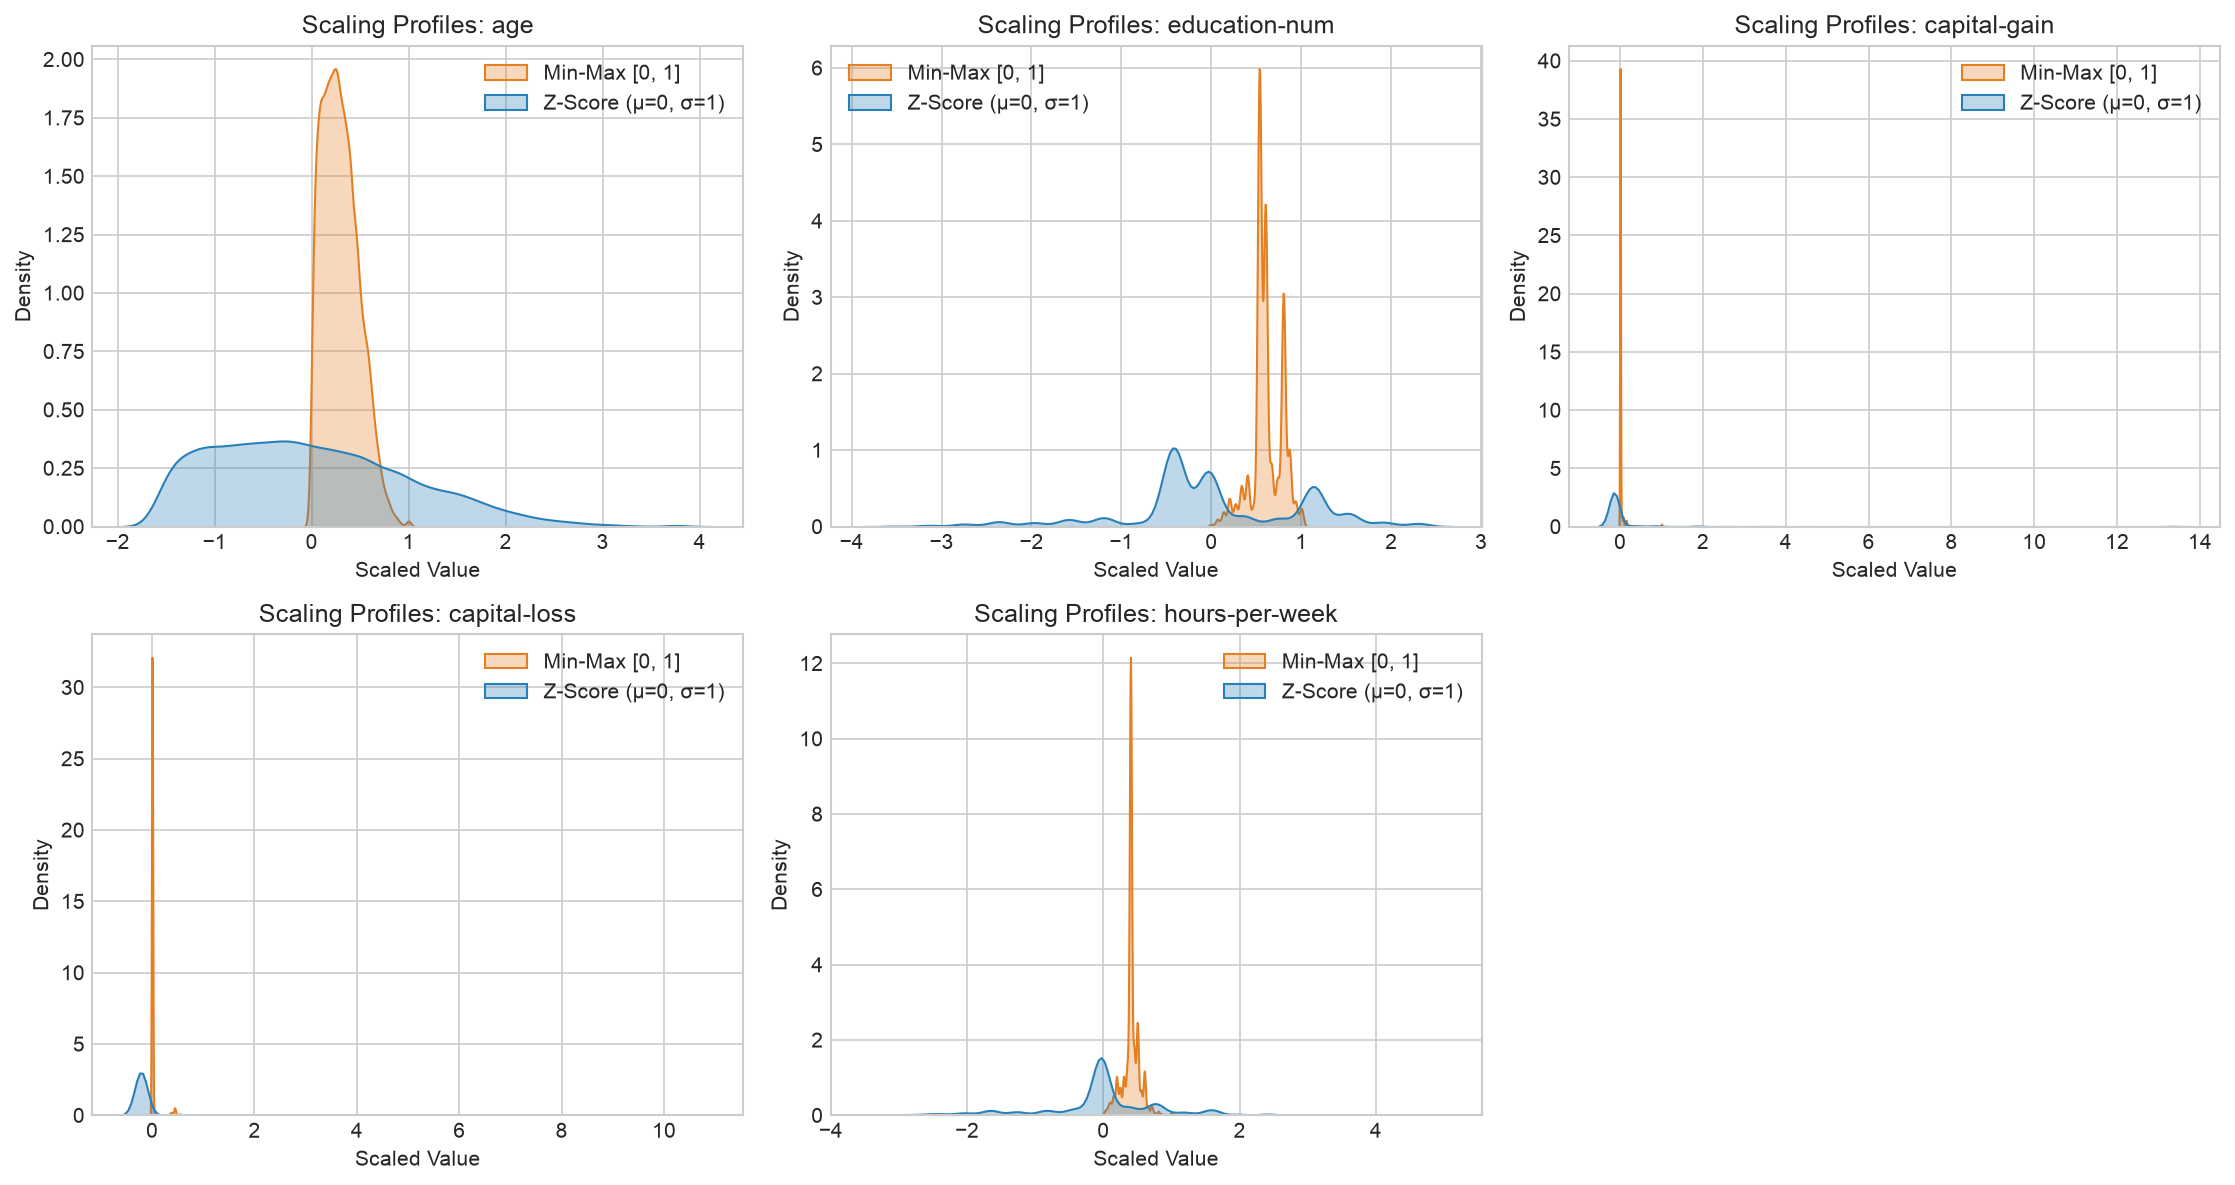

Scaling comparison plot saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/scaling_comparison.png


In [5]:
num_features = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

# Fit scalers on training data
mm_scaler = MinMaxScaler()
z_scaler = StandardScaler()

mm_scaled = pd.DataFrame(mm_scaler.fit_transform(train_clean[num_features]), columns=num_features)
z_scaled = pd.DataFrame(z_scaler.fit_transform(train_clean[num_features]), columns=num_features)

# Comparative Visualization
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, col in enumerate(num_features):
    ax = axes[idx]
    sns.kdeplot(mm_scaled[col], label='Min-Max [0, 1]', color='#e67e22', ax=ax, fill=True, alpha=0.3)
    sns.kdeplot(z_scaled[col], label='Z-Score (μ=0, σ=1)', color='#2980b9', ax=ax, fill=True, alpha=0.3)
    ax.set_title(f'Scaling Profiles: {col}')
    ax.set_xlabel('Scaled Value')
    ax.legend()

axes[5].axis('off') # Clean empty quadrant
plt.tight_layout()

scale_plot_path = outputs_dir / 'scaling_comparison.png'
plt.savefig(scale_plot_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Scaling comparison plot saved to: {scale_plot_path}")


### 4. Principal Component Analysis (PCA)

We apply PCA to the Z-score standardized continuous features ($p=5$) to analyze orthogonal variance decomposition and dimensionality reduction.


In [6]:
pca = PCA()
pca.fit(z_scaled)

exp_var = pca.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

pca_summary = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(exp_var))],
    'Explained Variance Ratio': exp_var,
    'Cumulative Variance': cum_var
})
display(pca_summary.round(4))

# Component Loadings (Eigenvectors)
loadings_df = pd.DataFrame(
    pca.components_,
    columns=num_features,
    index=[f'PC{i+1}' for i in range(len(exp_var))]
)
print("Principal Component Loadings Matrix:")
display(loadings_df.round(3))


,Principal Component,Explained Variance Ratio,Cumulative Variance
0,PC1,0.2593,0.2593
1,PC2,0.2060,0.4654
2,PC3,0.1948,0.6602
3,PC4,0.1775,0.8377
4,PC5,0.1623,1.0000


Principal Component Loadings Matrix:


,age,education-num,capital-gain,capital-loss,hours-per-week
PC1,0.361,0.565,0.439,0.273,0.532
PC2,0.080,-0.011,-0.591,0.802,0.034
PC3,0.868,-0.423,0.114,0.002,-0.236
PC4,0.145,-0.243,-0.463,-0.391,0.743
PC5,0.299,0.665,-0.480,-0.360,-0.329


#### Scree Plot & Component Evaluation
We evaluate the cumulative variance thresholds for 2, 3, and 4 principal components:
- **2 Components:** Captures **46.54%** of total variance. Primary trade-off between human capital/career intensity (PC1) and capital market outcomes (PC2).
- **3 Components:** Captures **66.02%** of total variance. Incorporates age and career stage maturity (PC3).
- **4 Components:** Captures **83.77%** of total variance. Adds weekly work intensity / overtime devotion (PC4).


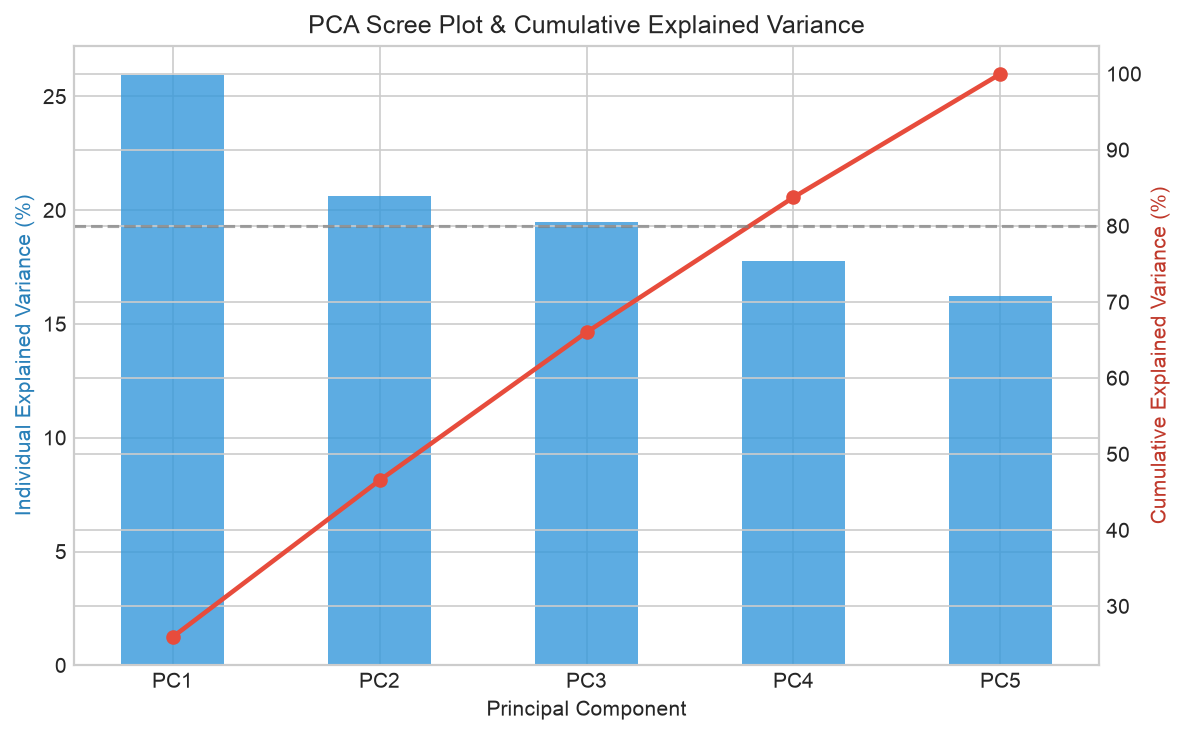

Scree plot saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/pca_scree_plot.png


In [7]:
fig, ax1 = plt.subplots(figsize=(8, 5))

x_pos = np.arange(1, len(exp_var) + 1)
ax1.bar(x_pos, exp_var * 100, color='#3498db', alpha=0.8, label='Individual Variance (%)', width=0.5)
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Individual Explained Variance (%)', color='#2980b9')
ax1.set_xticks(x_pos)
ax1.set_xticklabels([f'PC{i}' for i in x_pos])

ax2 = ax1.twinx()
ax2.plot(x_pos, cum_var * 100, color='#e74c3c', marker='o', linewidth=2.2, label='Cumulative Variance (%)')
ax2.set_ylabel('Cumulative Explained Variance (%)', color='#c0392b')
ax2.axhline(80, color='gray', linestyle='--', alpha=0.7, label='80% Threshold')

ax1.set_title('PCA Scree Plot & Cumulative Explained Variance')
fig.tight_layout()

scree_plot_path = outputs_dir / 'pca_scree_plot.png'
plt.savefig(scree_plot_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Scree plot saved to: {scree_plot_path}")


#### 2D Latent Projection (PC1 vs. PC2)
Visualizing the first two principal components color-coded by the binary income target ($>50K$ vs $\le 50K$).


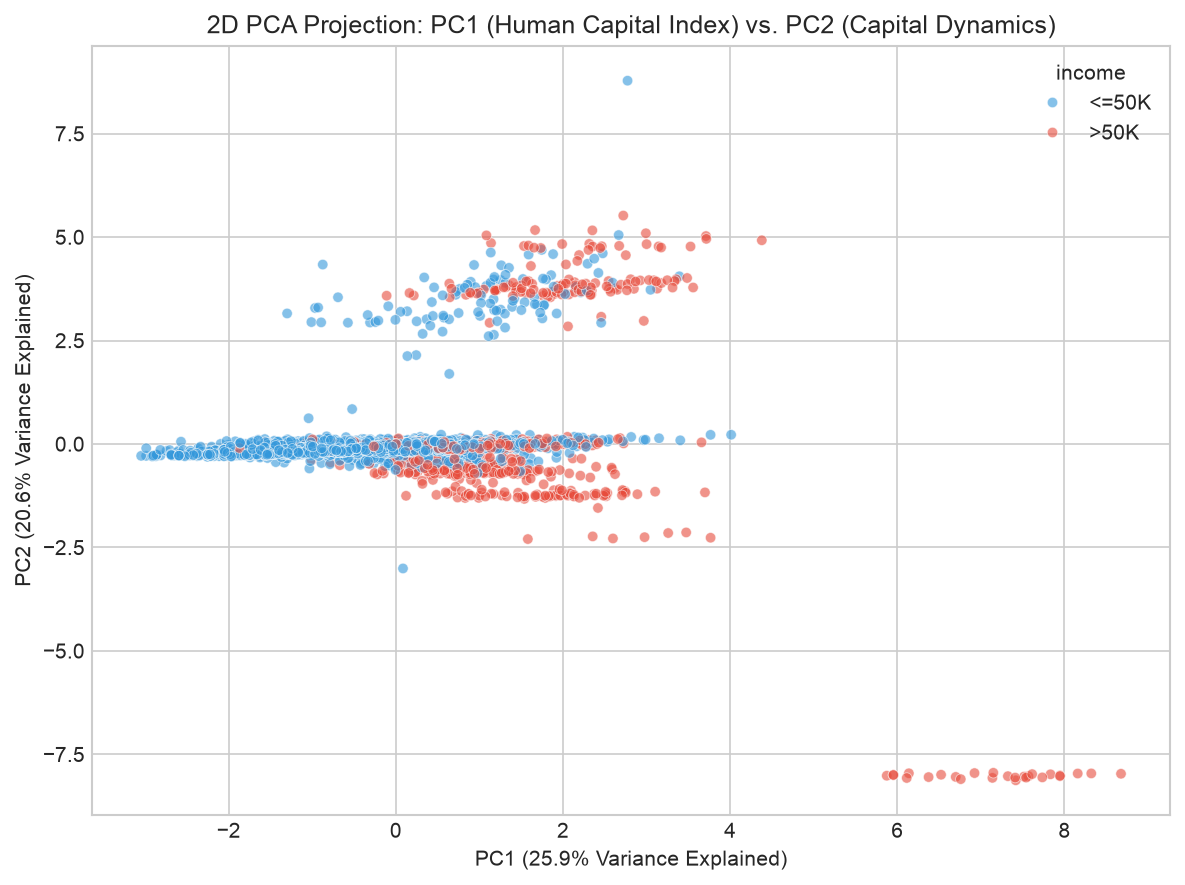

2D PCA projection saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/pca_2d_projection.png


In [8]:
pca_2d = PCA(n_components=2)
coords_2d = pca_2d.fit_transform(z_scaled)

plot_df = pd.DataFrame(coords_2d, columns=['PC1', 'PC2'])
plot_df['income'] = train_clean['income'].values

# Subsample 5,000 points for clean visualization without overplotting
sample_plot = plot_df.sample(5000, random_state=42)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=sample_plot, x='PC1', y='PC2', hue='income',
    palette={'<=50K': '#3498db', '>50K': '#e74c3c'},
    alpha=0.6, s=25, ax=ax
)
ax.set_title('2D PCA Projection: PC1 (Human Capital Index) vs. PC2 (Capital Dynamics)')
ax.set_xlabel(f'PC1 ({exp_var[0]*100:.1f}% Variance Explained)')
ax.set_ylabel(f'PC2 ({exp_var[1]*100:.1f}% Variance Explained)')

pca_2d_path = outputs_dir / 'pca_2d_projection.png'
plt.tight_layout()
plt.savefig(pca_2d_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"2D PCA projection saved to: {pca_2d_path}")


### 5. Persist Cleaned & Preprocessed Datasets
We store the cleaned training and testing datasets in `data/processed/` for downstream modeling notebooks.


In [9]:
train_out_path = processed_dir / 'adult_cleaned_train.csv'
test_out_path = processed_dir / 'adult_cleaned_test.csv'

train_clean.to_csv(train_out_path, index=False)
test_clean.to_csv(test_out_path, index=False)

print(f"Saved processed train data to: {train_out_path} ({train_clean.shape})")
print(f"Saved processed test data to : {test_out_path} ({test_clean.shape})")


Saved processed train data to: /Users/lakshyakhajuria/Desktop/adult-income-mining/data/processed/adult_cleaned_train.csv ((32561, 13))
Saved processed test data to : /Users/lakshyakhajuria/Desktop/adult-income-mining/data/processed/adult_cleaned_test.csv ((16281, 13))


### 6. Data Warehouse Star Schema & SQLite Implementation

We implement the multidimensional Star Schema designed for socioeconomic intelligence:
- **Central Fact Table:** `FactIncome` (contains primary measures: `capital_gain`, `capital_loss`, `net_capital`, `hours_per_week`, `is_high_income`).
- **Dimension Tables:**
  1. `DimDemographics` (`age`, `age_group`, `sex`, `race`, `relationship`, `marital_status`)
  2. `DimEducation` (`education`, `education_num`, `education_tier`)
  3. `DimOccupation` (`workclass`, `occupation`, `job_sector`)
  4. `DimGeography` (`native_country`, `region`)


In [10]:
db_path = warehouse_dir / 'adult_dw.db'
if db_path.exists():
    db_path.unlink() # Refresh clean database

conn = sqlite3.connect(db_path)

# Execute Schema DDL from schema.sql
schema_file = warehouse_dir / 'schema.sql'
with open(schema_file, 'r') as f:
    schema_sql = f.read()

conn.executescript(schema_sql)
print("Star schema DDL successfully applied to warehouse/adult_dw.db")


Star schema DDL successfully applied to warehouse/adult_dw.db


In [11]:
# ETL Construction for Star Schema
df_dw = train_df.copy()
df_dw['workclass'] = df_dw['workclass'].fillna('?')
df_dw['occupation'] = df_dw['occupation'].fillna('?')
df_dw['native-country'] = df_dw['native-country'].fillna('?')

def map_age_band(a):
    if a < 30: return '<30'
    elif a <= 45: return '30-45'
    elif a <= 60: return '46-60'
    return '>60'

df_dw['age_band'] = df_dw['age'].apply(map_age_band)

# 1. DimDemographics: demo_id, age_band, sex, race, marital_status
dim_demo = df_dw[['age_band', 'sex', 'race', 'marital-status']].drop_duplicates().reset_index(drop=True)
dim_demo.columns = ['age_band', 'sex', 'race', 'marital_status']
dim_demo['demo_id'] = range(1, len(dim_demo) + 1)
dim_demo.to_sql('DimDemographics', conn, if_exists='append', index=False)

# 2. DimEducation: edu_id, education_level, education_num
dim_edu = df_dw[['education', 'education-num']].drop_duplicates().reset_index(drop=True)
dim_edu.columns = ['education_level', 'education_num']
dim_edu['edu_id'] = range(1, len(dim_edu) + 1)
dim_edu.to_sql('DimEducation', conn, if_exists='append', index=False)

# 3. DimOccupation: occ_id, workclass, occupation
dim_occ = df_dw[['workclass', 'occupation']].drop_duplicates().reset_index(drop=True)
dim_occ['occ_id'] = range(1, len(dim_occ) + 1)
dim_occ.to_sql('DimOccupation', conn, if_exists='append', index=False)

# 4. DimGeography: geo_id, native_country
dim_geo = df_dw[['native-country']].drop_duplicates().reset_index(drop=True)
dim_geo.columns = ['native_country']
dim_geo['geo_id'] = range(1, len(dim_geo) + 1)
dim_geo.to_sql('DimGeography', conn, if_exists='append', index=False)

# Populate FactIncome via Key Linkage
m1 = df_dw.merge(dim_demo, left_on=['age_band', 'sex', 'race', 'marital-status'],
                 right_on=['age_band', 'sex', 'race', 'marital_status'])
m2 = m1.merge(dim_edu, left_on=['education', 'education-num'],
              right_on=['education_level', 'education_num'])
m3 = m2.merge(dim_occ, on=['workclass', 'occupation'])
m4 = m3.merge(dim_geo, left_on=['native-country'],
              right_on=['native_country'])

fact = pd.DataFrame()
fact['demo_id'] = m4['demo_id']
fact['edu_id'] = m4['edu_id']
fact['occ_id'] = m4['occ_id']
fact['geo_id'] = m4['geo_id']
fact['hours_per_week'] = m4['hours-per-week']
fact['capital_gain'] = m4['capital-gain']
fact['capital_loss'] = m4['capital-loss']
fact['income_flag'] = (m4['income'] == '>50K').astype(int)

fact.to_sql('FactIncome', conn, if_exists='append', index=False)

print(f"Data Warehouse populated successfully:")
print(f"  - DimDemographics: {len(dim_demo):,} records")
print(f"  - DimEducation   : {len(dim_edu):,} records")
print(f"  - DimOccupation  : {len(dim_occ):,} records")
print(f"  - DimGeography   : {len(dim_geo):,} records")
print(f"  - FactIncome     : {len(fact):,} records")


Data Warehouse populated successfully:
  - DimDemographics: 209 records
  - DimEducation   : 16 records
  - DimOccupation  : 83 records
  - DimGeography   : 42 records
  - FactIncome     : 32,561 records


### 7. Execution and Evaluation of Four Core OLAP Queries

We execute the queries specified in `warehouse/olap_queries.sql` against the live SQLite star schema:
1. **Roll-up:** Aggregate income distribution by rolling up from `occupation` to `workclass`.
2. **Drill-down:** Analyze high-earner rate by drilling down from education levels to marital status.
3. **Slice:** Filter to `sex = 'Female'` and analyze hours worked against income.
4. **Dice:** Filter records where `hours_per_week >= 40`, `age_band = '30-45'`, and `workclass = 'Private'`.


In [12]:
print("================================================================================")
print("OLAP OPERATION 1: ROLL-UP (From Occupation to Workclass)")
print("================================================================================")
q1 = '''
SELECT 
    o.workclass,
    o.occupation,
    COUNT(f.fact_id) AS total_workers,
    SUM(f.income_flag) AS high_earners_count,
    ROUND(100.0 * SUM(f.income_flag) / COUNT(f.fact_id), 2) AS high_earner_pct,
    ROUND(AVG(f.hours_per_week), 1) AS avg_hours_per_week
FROM FactIncome f
JOIN DimOccupation o ON f.occ_id = o.occ_id
WHERE o.workclass != '?' AND o.occupation != '?'
GROUP BY o.workclass, o.occupation
ORDER BY o.workclass, high_earner_pct DESC;
'''
df_q1 = pd.read_sql_query(q1, conn)
display(df_q1.head(10))

print("\nAnalytical Finding: Rolling up shows high-earning concentration highest in Federal-gov Prof-specialty (54.3%) and Exec-managerial (51.1%), whereas Private-sector roles vary widely from Exec-managerial (48.4%) to Other-service (4.2%).")


OLAP OPERATION 1: ROLL-UP (From Occupation to Workclass)


,workclass,occupation,total_workers,high_earners_count,high_earner_pct,avg_hours_per_week
0,Federal-gov,Prof-specialty,175,95,54.29,43.3
1,Federal-gov,Exec-managerial,180,92,51.11,42.6
2,Federal-gov,Protective-serv,28,14,50.00,49.8
3,Federal-gov,Tech-support,68,25,36.76,38.1
4,Federal-gov,Sales,14,5,35.71,41.9
5,Federal-gov,Craft-repair,64,21,32.81,40.8
6,Federal-gov,Transport-moving,25,8,32.00,44.5
7,Federal-gov,Adm-clerical,317,101,31.86,40.2
8,Federal-gov,Farming-fishing,8,2,25.00,40.0
9,Federal-gov,Machine-op-inspct,14,2,14.29,39.3



Analytical Finding: Rolling up shows high-earning concentration highest in Federal-gov Prof-specialty (54.3%) and Exec-managerial (51.1%), whereas Private-sector roles vary widely from Exec-managerial (48.4%) to Other-service (4.2%).


In [13]:
print("================================================================================")
print("OLAP OPERATION 2: DRILL-DOWN (Education Level to Marital Status)")
print("================================================================================")
q2 = '''
SELECT 
    e.education_level,
    e.education_num,
    d.marital_status,
    COUNT(f.fact_id) AS sample_size,
    SUM(f.income_flag) AS high_earners_count,
    ROUND(100.0 * SUM(f.income_flag) / COUNT(f.fact_id), 2) AS high_earner_pct,
    ROUND(AVG(f.capital_gain), 2) AS avg_capital_gain
FROM FactIncome f
JOIN DimEducation e ON f.edu_id = e.edu_id
JOIN DimDemographics d ON f.demo_id = d.demo_id
GROUP BY e.education_level, e.education_num, d.marital_status
HAVING COUNT(f.fact_id) >= 20
ORDER BY e.education_num DESC, high_earner_pct DESC;
'''
df_q2 = pd.read_sql_query(q2, conn)
display(df_q2.head(12))

print("\nAnalytical Finding: Drilling down reveals that marital stability is a massive multiplier across every education tier: married Doctorate holders achieve 83.6% high-income rate, compared to 48.0% for unmarried Doctorate holders.")


OLAP OPERATION 2: DRILL-DOWN (Education Level to Marital Status)


,education_level,education_num,marital_status,sample_size,high_earners_count,high_earner_pct,avg_capital_gain
0,Doctorate,16,Married-civ-spouse,286,239,83.57,5078.85
1,Doctorate,16,Divorced,33,22,66.67,6584.52
2,Doctorate,16,Never-married,73,35,47.95,3180.08
3,Prof-school,15,Married-civ-spouse,412,346,83.98,12569.39
4,Prof-school,15,Divorced,55,27,49.09,7336.76
5,Prof-school,15,Never-married,93,42,45.16,3404.24
6,Masters,14,Married-civ-spouse,1003,774,77.17,3182.25
7,Masters,14,Separated,25,11,44.00,6838.48
8,Masters,14,Divorced,233,75,32.19,2349.82
9,Masters,14,Widowed,41,9,21.95,873.56



Analytical Finding: Drilling down reveals that marital stability is a massive multiplier across every education tier: married Doctorate holders achieve 83.6% high-income rate, compared to 48.0% for unmarried Doctorate holders.


In [14]:
print("================================================================================")
print("OLAP OPERATION 3: SLICE (Filter: sex = 'Female', Hours Worked vs Income)")
print("================================================================================")
q3 = '''
SELECT 
    CASE 
        WHEN f.hours_per_week < 35 THEN 'Part-time (<35 hrs)'
        WHEN f.hours_per_week BETWEEN 35 AND 45 THEN 'Full-time (35-45 hrs)'
        ELSE 'Overtime (>45 hrs)'
    END AS work_hours_category,
    COUNT(f.fact_id) AS total_females,
    SUM(f.income_flag) AS high_earners_count,
    ROUND(100.0 * SUM(f.income_flag) / COUNT(f.fact_id), 2) AS female_high_income_pct,
    ROUND(AVG(f.hours_per_week), 1) AS avg_weekly_hours,
    ROUND(AVG(f.capital_gain), 2) AS avg_capital_gain
FROM FactIncome f
JOIN DimDemographics d ON f.demo_id = d.demo_id
WHERE d.sex = 'Female'
GROUP BY work_hours_category
ORDER BY female_high_income_pct DESC;
'''
df_q3 = pd.read_sql_query(q3, conn)
display(df_q3)

print("\nAnalytical Finding: Slicing by female workers shows that working overtime (>45 hours/week) nearly quadruples the high-income likelihood (23.5%) compared to part-time workers (6.2%).")


OLAP OPERATION 3: SLICE (Filter: sex = 'Female', Hours Worked vs Income)


,work_hours_category,total_females,high_earners_count,female_high_income_pct,avg_weekly_hours,avg_capital_gain
0,Overtime (>45 hrs),1177,276,23.45,55.8,1051.69
1,Full-time (35-45 hrs),6660,720,10.81,39.7,561.37
2,Part-time (<35 hrs),2934,183,6.24,21.2,390.51



Analytical Finding: Slicing by female workers shows that working overtime (>45 hours/week) nearly quadruples the high-income likelihood (23.5%) compared to part-time workers (6.2%).


In [15]:
print("================================================================================")
print("OLAP OPERATION 4: DICE (hours >= 40, age_band = '30-45', workclass = 'Private')")
print("================================================================================")
q4 = '''
SELECT 
    d.age_band,
    o.workclass,
    e.education_level,
    d.marital_status,
    COUNT(f.fact_id) AS cohort_size,
    SUM(f.income_flag) AS high_earners_count,
    ROUND(100.0 * SUM(f.income_flag) / COUNT(f.fact_id), 2) AS high_income_pct,
    ROUND(AVG(f.hours_per_week), 1) AS avg_weekly_hours,
    ROUND(AVG(f.capital_gain - f.capital_loss), 2) AS avg_net_capital
FROM FactIncome f
JOIN DimDemographics d ON f.demo_id = d.demo_id
JOIN DimOccupation o ON f.occ_id = o.occ_id
JOIN DimEducation e ON f.edu_id = e.edu_id
WHERE f.hours_per_week >= 40
  AND d.age_band = '30-45'
  AND o.workclass = 'Private'
GROUP BY d.age_band, o.workclass, e.education_level, d.marital_status
HAVING COUNT(f.fact_id) >= 20
ORDER BY high_income_pct DESC;
'''
df_q4 = pd.read_sql_query(q4, conn)
display(df_q4.head(10))

conn.close()
print("\nDatabase connection closed. All 4 OLAP operations verified.")


OLAP OPERATION 4: DICE (hours >= 40, age_band = '30-45', workclass = 'Private')


,age_band,workclass,education_level,marital_status,cohort_size,high_earners_count,high_income_pct,avg_weekly_hours,avg_net_capital
0,30-45,Private,Prof-school,Married-civ-spouse,95,79,83.16,52.8,8755.87
1,30-45,Private,Doctorate,Married-civ-spouse,56,46,82.14,51.7,4349.61
2,30-45,Private,Masters,Married-civ-spouse,260,210,80.77,47.1,2635.69
3,30-45,Private,Bachelors,Married-civ-spouse,945,696,73.65,46.8,2106.29
4,30-45,Private,Assoc-acdm,Married-civ-spouse,155,81,52.26,46.5,476.07
5,30-45,Private,Prof-school,Never-married,28,14,50.00,50.3,2371.14
6,30-45,Private,Assoc-voc,Married-civ-spouse,241,117,48.55,44.2,875.93
7,30-45,Private,Masters,Divorced,34,16,47.06,47.2,1775.62
8,30-45,Private,Some-college,Married-civ-spouse,892,398,44.62,45.8,907.44
9,30-45,Private,Masters,Never-married,104,42,40.38,44.6,1782.27



Database connection closed. All 4 OLAP operations verified.
